# Pendulum Mode

optimal diameter to nullify thermal Noise =  0.0008222668942759311
Dilution Factor 296.677207510794
Resonant angular frequency ω₀ = 4.036790936266446 rad/s
Resonant frequency f₀ = 0.642475231735365 Hz
Thermal loss matrix =  [0. 0. 0. ... 0. 0. 0.]
Bulk loss matrix =  [2.07185726e-12 2.07295962e-12 2.07406257e-12 ... 8.62775507e-08
 8.63234560e-08 8.63693857e-08]
Surface Loss matrix =  [5.9834587e-08 5.9834587e-08 5.9834587e-08 ... 5.9834587e-08 5.9834587e-08
 5.9834587e-08]
Total loss =  [2.07302989e-10 2.07302993e-10 2.07302996e-10 ... 4.98108877e-10
 4.98263609e-10 4.98418422e-10]


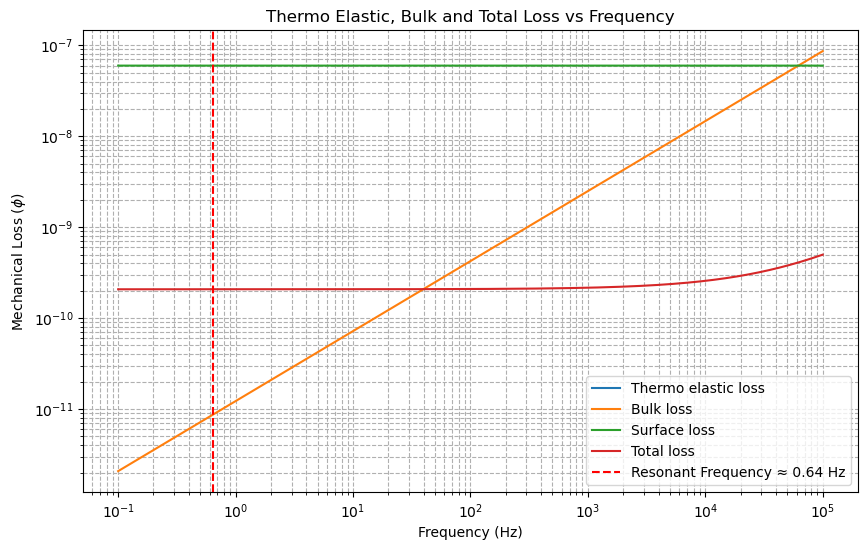

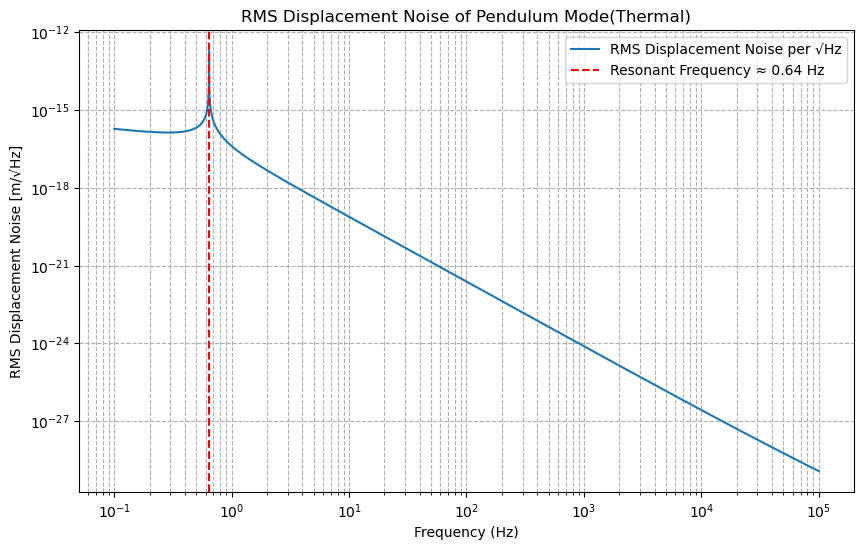

Resonant angular frequency ω₀ = 4.036790936266446 rad/s
Resonant frequency f₀ = 0.642475231735365 Hz


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
k_B = 1.380649e-23 #m^2 kg s^-2 K^-1
T = 300 #K   
m = 10#mass            
g = 9.81 #m/s^2         
l = 0.602 #m
Y = 72e9 #(N/m²)/Pa
rho=2200 #density
C=703#specific heat
alpha=3.9e-7 #coefficient of thermal expansion
d=800e-6 #diameter of the fiber
C2=1.22e-11
hphi_s=6.15e-12 #product of the mechanical loss of the material surface, φs and the depth ,h
beta=1.52e-4 #
Kappa=1.38 #W/mK (thermal Conductivity)

#*****************************************************************#
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)
print("optimal diameter to nullify thermal Noise = ",optimal_diameter)
#*****************************************************************#

###################################################################
sigma_0 = (m* g) / (np.pi * (optimal_diameter / 2)**2) #static stress(F/Area)
###################################################################

###################################################################
#Thermal Relaxation time to nullify Thermal Loss
tau=(1/(4.32*np.pi))*(rho*C*optimal_diameter*optimal_diameter)/Kappa 
###################################################################

###################################################################
#Moment of Inertia
I=np.pi*optimal_diameter**4/64 
###################################################################

Dil_Fact1=2*l*(np.sqrt((m*g)/(Y*I)))
print("Dilution Factor",Dil_Fact1)

omega_0 = np.sqrt(g / l) # resonant angular frequency
print("Resonant angular frequency ω₀ =", omega_0, "rad/s")
f0_hz = omega_0 / (2 * np.pi)# resonant frequency
print("Resonant frequency f₀ =", f0_hz, "Hz")

# Frequency range: 0.1 Hz to 100000 Hz
f_values = np.logspace(-1, 5, 20000)
omega_values = 2 * np.pi * f_values

###################################################################
#Thermo elastic loss
def phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau):
    thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    prefactor = (Y * T) / (rho * C)
    return prefactor * thermo_factor * ((omega_values * tau) / (1 + (omega_values * tau)**2))
Thermo_phi1=phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau)
print("Thermal loss matrix = ",Thermo_phi1)
###################################################################


###################################################################
#bul loss
def phi_bulk1(omega_values, C2):
    return C2 * (omega_values / (2 * np.pi))**0.77
bulk_phi1=phi_bulk1(omega_values, C2)
print("Bulk loss matrix = ",bulk_phi1)
###################################################################


###################################################################
#surface loss
def phi_surface1(hphi_s,optimal_diameter):
    return 8*hphi_s/optimal_diameter
surface_phi1=phi_surface1(hphi_s,optimal_diameter)
array1=np.ones_like(f_values)
surface_phi1=surface_phi1*array1
print("Surface Loss matrix = ",surface_phi1)
###################################################################

###################################################################
#change total phi calculation
def total_phi1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2):
    return phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau) + phi_bulk1(omega_values, C2)+ phi_surface1(hphi_s,d)

phi_total_values1 =total_phi1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2)/Dil_Fact1
print("Total loss = ",phi_total_values1)
###################################################################


def power_spectral_density1(omega, k_B, T, m, omega_0, phi_total_values1):
    numerator = omega_0**2 * phi_total_values1
    denominator = (omega_0**4 * phi_total_values1**2) + (omega_0**2 - omega**2)**2
    prefactor = (4 * k_B * T) / (m * (omega))
    return prefactor * (numerator / denominator)

# Compute PSD
psd_values1 = power_spectral_density1(omega_values, k_B, T, m, omega_0,phi_total_values1)

#printing losses against frequency
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi1, label='Thermo elastic loss')
# Plot Bulk loss
plt.loglog(f_values, bulk_phi1, label='Bulk loss')
# Plot Surface loss
plt.loglog(f_values, surface_phi1, label='Surface loss')
# Plot total loss
plt.loglog(f_values, phi_total_values1, label='Total loss')
# Add the resonant frequency line
plt.axvline(x=f0_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_hz:.2f} Hz')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Loss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()

# Plot RMS Displacement Noise (per √Hz)
plt.figure(figsize=(10, 6))
plt.loglog(f_values, np.sqrt(psd_values1), label='RMS Displacement Noise per √Hz')
plt.axvline(x=f0_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_hz:.2f} Hz')
plt.title('RMS Displacement Noise of Pendulum Mode(Thermal)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/√Hz]')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

print("Resonant angular frequency ω₀ =", omega_0, "rad/s")
print("Resonant frequency f₀ =", f0_hz, "Hz")

# Bounce/Vertical Mode

optimal diameter to nullify thermal Noise =  0.0008222668942759311
Dilution Factor 1
fiber Area =  1.2566370614359172e-07
spring constant =  15029.546249731902
Resonant angular frequency ω₀ = 54.82617303757741 rad/s
Resonant frequency f₀ = 8.72585644974204 Hz
Thermal loss matrix =  [0. 0. 0. ... 0. 0. 0.]
Bulk loss matrix =  [2.07185726e-12 2.07295962e-12 2.07406257e-12 ... 8.62775507e-08
 8.63234560e-08 8.63693857e-08]
Surface Loss matrix =  1.23e-07
Surface Loss matrix =  [1.23e-07 1.23e-07 1.23e-07 ... 1.23e-07 1.23e-07 1.23e-07]
Total loss =  [1.23002072e-07 1.23002073e-07 1.23002074e-07 ... 2.09277551e-07
 2.09323456e-07 2.09369386e-07]


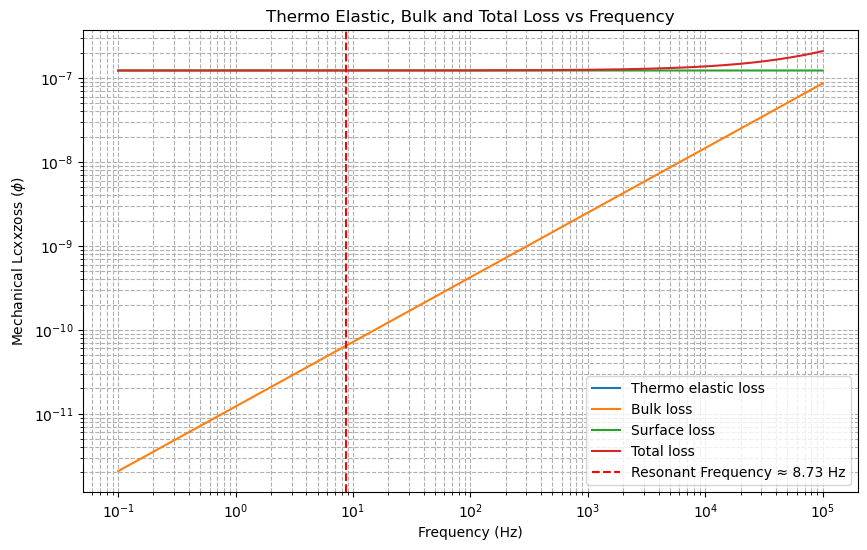

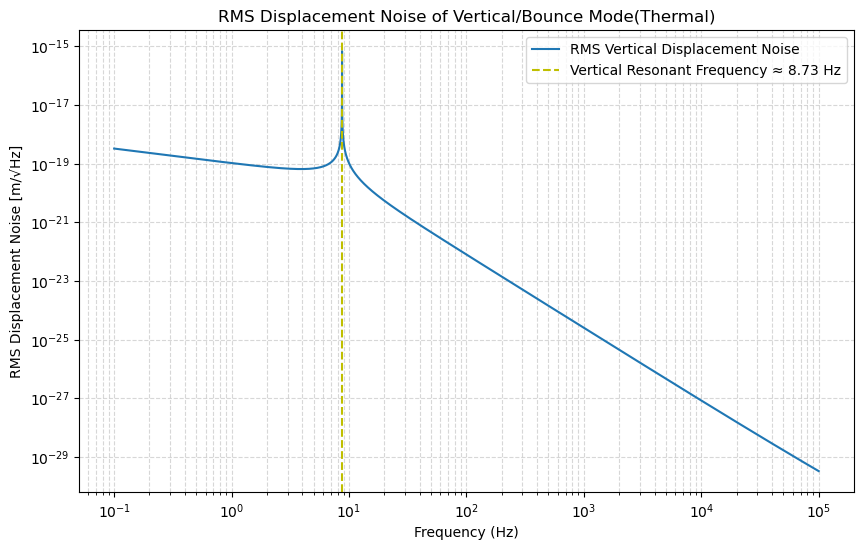

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
k_B = 1.380649e-23 #m^2 kg s^-2 K^-1
T = 300 #K   
m = 10#mass 
m1=((m*m)/(m+m))
g = 9.81 #m/s^2         
l = 0.602 #m
Y = 72e9 #(N/m²)/Pa
rho=2200 #density
C=703#specific heat
alpha=3.9e-7 #coefficient of thermal expansion
d=800e-6 #diameter of the fiber
d1=400e-6
C2=1.22e-11
hphi_s=6.15e-12 #product of the mechanical loss of the material surface, φs and the depth ,h
beta=1.52e-4 #
Kappa=1.38 #W/mK (thermal Conductivity)

#*****************************************************************#
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)
print("optimal diameter to nullify thermal Noise = ",optimal_diameter)
#*****************************************************************#

###################################################################
sigma_0 = (m* g) / (np.pi * (optimal_diameter / 2)**2) #static stress(F/Area)
###################################################################

###################################################################
#Thermal Relaxation time to nullify Thermal Loss
tau=(1/(4.32*np.pi))*(rho*C*optimal_diameter*optimal_diameter)/Kappa 
###################################################################

###################################################################
#Moment of Inertia
I=np.pi*optimal_diameter**4/64 
###################################################################

Dil_Fact2=1
print("Dilution Factor",Dil_Fact2)

A_fiber = np.pi * (d1 / 2)**2 # fiber cross section Area (here 400 microns used as spring mode is at this diameter)
print("fiber Area = ",A_fiber)
k_fiber = (Y * A_fiber) / l #spring constant
print("spring constant = ",k_fiber)
omega_0_vertical = np.sqrt(k_fiber / m1) # Angular Resonant Frequency for vertical mode
print("Resonant angular frequency ω₀ =", omega_0_vertical, "rad/s")
f0_vertical_hz = omega_0_vertical / (2 * np.pi) # vertical resonant freq calculation
print("Resonant frequency f₀ =", f0_vertical_hz, "Hz")
,
# Frequency range: 0.1 Hz to 100000 Hz
f_values = np.logspace(-1, 5, 20000)
omega_values = 2 * np.pi * f_values

###################################################################
#Thermoelastic Loss,set to 0
#def phi_thermo2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau):
    #thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    #prefactor = (Y * T) / (rho * C)
    #return prefactor * thermo_factor * ((omega_values * tau) / (1 + (omega_values * tau)**2))
#Thermo_phi2=phi_thermo2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau)
Thermo_phi2=0*np.ones_like(f_values)
print("Thermal loss matrix = ",Thermo_phi2)
###################################################################

def phi_bulk2(omega, C2):
    return C2 * (omega / (2 * np.pi))**0.77
bulk_phi2=phi_bulk2(omega_values, C2)
print("Bulk loss matrix = ",bulk_phi2)


###################################################################
def phi_surface2(hphi_s, d1):#800 microns/400 microns doubt
    return 8 * hphi_s / d1
surface_phi2=phi_surface2(hphi_s,d1)
print("Surface Loss matrix = ",surface_phi2)
array2=np.ones_like(f_values)
surface_phi2=surface_phi2*array2
print("Surface Loss matrix = ",surface_phi2)
###################################################################

###################################################################
#Total phi
def total_phi2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2, hphi_s, d1):
    surface_loss = phi_surface2(hphi_s, d1)
    return phi_bulk2(omega_values, C2) + surface_loss
phi_total_values2 =total_phi2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2,hphi_s, d1)/Dil_Fact2
print("Total loss = ",phi_total_values2)
###################################################################

def power_spectral_density2(omega_values, k_B, T, m, omega_0_vertical, phi_total_values2):
    numerator = omega_0_vertical**2 * phi_total_values2
    denominator = (omega_0_vertical**4 * phi_total_values2**2) + (omega_0_vertical**2 - omega_values**2)**2
    prefactor = (4 * k_B * T) / (m * (omega_values))
    return prefactor * (numerator / denominator)

# PSD for vertical freq
psd_values2 = power_spectral_density2(omega_values, k_B, T, m, omega_0_vertical, phi_total_values2)
psd_values2=psd_values2*0.000001

#printing losses against frequency
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi2, label='Thermo elastic loss')
# Plot Bulk loss 
plt.loglog(f_values, bulk_phi2, label='Bulk loss')
# Plot Surface loss 
plt.loglog(f_values, surface_phi2, label='Surface loss')
# Plot Total loss
plt.loglog(f_values, phi_total_values2, label='Total loss')
# Add the resonant frequency line
plt.axvline(x=f0_vertical_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_vertical_hz:.2f} Hz')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Lcxxzoss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()

# Plot
plt.figure(figsize=(10, 6))
plt.loglog(f_values,np.sqrt(psd_values2), label='RMS Vertical Displacement Noise')
plt.axvline(x=f0_vertical_hz, color='y', linestyle='--', label=f'Vertical Resonant Frequency ≈ {f0_vertical_hz:.2f} Hz')

plt.title('RMS Displacement Noise of Vertical/Bounce Mode(Thermal)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/√Hz]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()


# Violin Mode

optimal diameter to nullify thermal Noise =  0.0008222668942759311
Dilution Factor 148.338603755397
Thermal loss matrix =  [0. 0. 0. ... 0. 0. 0.]
Bulk loss matrix =  [2.07185726e-12 2.07295962e-12 2.07406257e-12 ... 8.62775507e-08
 8.63234560e-08 8.63693857e-08]
Surface Loss matrix =  6.15e-08
Surface Loss matrix =  [6.15e-08 6.15e-08 6.15e-08 ... 6.15e-08 6.15e-08 6.15e-08]
Total loss =  [8.29197989e-10 8.29197996e-10 8.29198003e-10 ... 1.41080976e-09
 1.41111923e-09 1.41142886e-09]
Combined Modes: [1, 2]
Violin Mode 1 at f₀ = 494.76 Hz
Violin Mode 2 at f₀ = 989.51 Hz


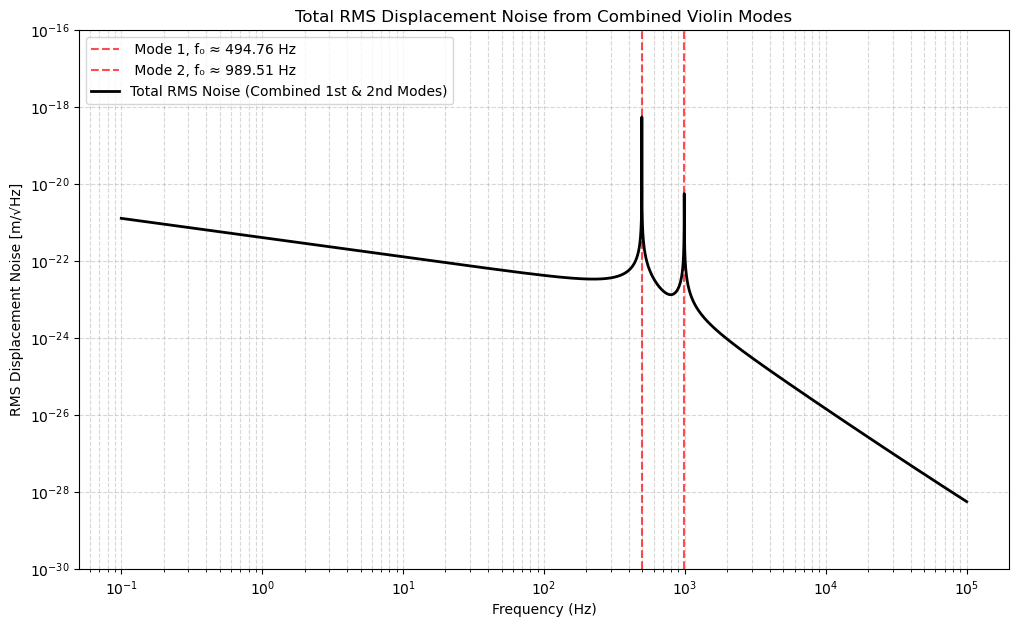

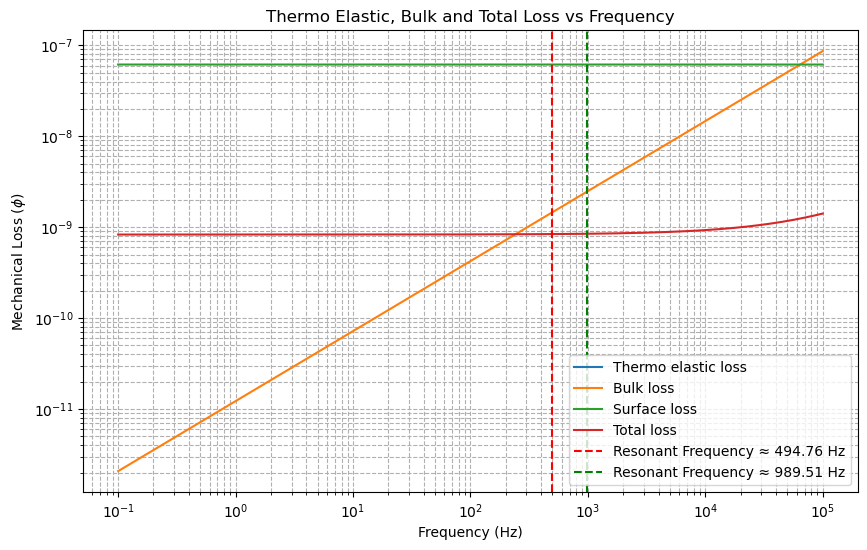

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
k_B = 1.380649e-23 #m^2 kg s^-2 K^-1
T = 300 #K   
m = 10#mass 
m1=((m*m)/(m+m))
g = 9.81 #m/s^2         
l = 0.602 #m
Y = 72e9 #(N/m²)/Pa
rho=2200 #density
C=703#specific heat
alpha=3.9e-7 #coefficient of thermal expansion
d=800e-6 #diameter of the fiber
d1=400e-6
C2=1.22e-11
hphi_s=6.15e-12 #product of the mechanical loss of the material surface, φs and the depth ,h
beta=1.52e-4 #
Kappa=1.38 #W/mK (thermal Conductivity)
vfiber=(np.pi*(3e-3/2)**2)*10e-3+(np.pi*(800e-6/2)**2)*20e-3+(np.pi*(400e-6/2)**2)*596e-3
mfiber=rho*vfiber


#*****************************************************************#
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)
print("optimal diameter to nullify thermal Noise = ",optimal_diameter)
#*****************************************************************#

###################################################################
sigma_0 = (m* g) / (np.pi * (optimal_diameter / 2)**2) #static stress(F/Area)
###################################################################

###################################################################
#Thermal Relaxation time to nullify Thermal Loss
tau=(1/(4.32*np.pi))*(rho*C*optimal_diameter*optimal_diameter)/Kappa 
###################################################################

###################################################################
#Moment of Inertia
I=np.pi*optimal_diameter**4/64 
###################################################################

###################################################################
Dil_Fact3=l*(np.sqrt((m*g)/(Y*I)))#Taken D/2 as per advised
print("Dilution Factor",Dil_Fact3)
###################################################################
f_values = np.logspace(-1, 5, 20000)
omega_values = 2 * np.pi * f_values

T_tension = m * g
A_fiber = np.pi * (d1 / 2)**2
mu = rho * A_fiber

###################################################################
#Thermo Elastic Loss
def phi_thermo3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau):
    thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    prefactor = (Y * T) / (rho * C)
    return prefactor * thermo_factor * ((omega_values * tau) / (1 + (omega_values * tau)**2))
Thermo_phi3=phi_thermo3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau)
print("Thermal loss matrix = ",Thermo_phi3)
###################################################################

#Bulk Loss
def phi_bulk3(omega_values, C2):
    return C2 * (omega_values / (2 * np.pi))**0.77
bulk_phi3=phi_bulk3(omega_values, C2)
print("Bulk loss matrix = ",bulk_phi3)
###################################################################

#Surface loss
def phi_surface3(hphi_s, d):#800 microns/400 microns doubt
    return 8 * hphi_s / d
surface_phi3=phi_surface3(hphi_s,d)
print("Surface Loss matrix = ",surface_phi3)
array3=np.ones_like(f_values)
surface_phi3=surface_phi3*array3
print("Surface Loss matrix = ",surface_phi3)
###################################################################

###################################################################
#Total Phi
def total_phi3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2, hphi_s, d1):
    surface_loss = phi_surface3(hphi_s, d1)
    return phi_thermo3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau) + phi_bulk3(omega_values, C2) + surface_loss
phi_total_values3 =total_phi3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2,hphi_s, d1)/Dil_Fact3
print("Total loss = ",phi_total_values3)
###################################################################

###################################################################
#PSD
def power_spectral_density3(omega_values, k_B, T, m, omega_0, total_phi_values, mfiber, n):
    numerator = omega_0**2 * total_phi_values
    denominator = (omega_0**4 * total_phi_values**2) + (omega_0**2 - omega_values**2)**2
    prefactor = (4 * k_B * T) * (2 * mfiber) / (m**2 * (np.pi)**2 * n**2)
    return (prefactor / (omega_values)) * (numerator / denominator)
###################################################################

#Total PSD and Plot
total_psd3 = np.zeros_like(f_values)
plt.figure(figsize=(12, 7))

#Sum PSDs
modes = [1, 2]

print("Combined Modes: " + str(modes))
for n in modes:
    #resonant frequency for the current mode 'n'
    f0_violin_hz = (n / (2 * l)) * np.sqrt(T_tension / mu)
    omega_0 = 2 * np.pi * f0_violin_hz
    if n==1:
        f1=f0_violin_hz
    else:
        f2=f0_violin_hz

    psd_values3 = power_spectral_density3(omega_values, k_B, T, m, omega_0, phi_total_values3, mfiber, n)

    #to find total psd
    total_psd3 += psd_values3

    #vertical line to mark the frequency of the individual modes
    plt.axvline(x=f0_violin_hz, color='r', linestyle='--', alpha=0.7, label=f' Mode {n}, f₀ ≈ {f0_violin_hz:.2f} Hz')
    print("Violin Mode "+ str(n)+" at f₀ = " + str(round(f0_violin_hz, 2)) + " Hz")

# Plot the square root of the total PSD to get RMS Displacement Noise
plt.loglog(f_values, np.sqrt(total_psd3), label='Total RMS Noise (Combined 1st & 2nd Modes)', color='k', linewidth=2)

#plot
plt.title('Total RMS Displacement Noise from Combined Violin Modes')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/√Hz]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.ylim(1e-30, 1e-16) # Adjusted y-limits for better viewing
plt.show()


#printing losses against frequency
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi3, label='Thermo elastic loss')
# Plot Bulk loss 
plt.loglog(f_values, bulk_phi3, label='Bulk loss')
# Plot Surface loss 
plt.loglog(f_values, surface_phi3, label='Surface loss')
# Plot Total loss
plt.loglog(f_values, phi_total_values3, label='Total loss')
# Add the resonant frequency line
plt.axvline(x=f1, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f1:.2f} Hz')
# Add the resonant frequency line
plt.axvline(x=f2, color='g', linestyle='--', label=f'Resonant Frequency ≈ {f2:.2f} Hz')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Loss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()


# Combined

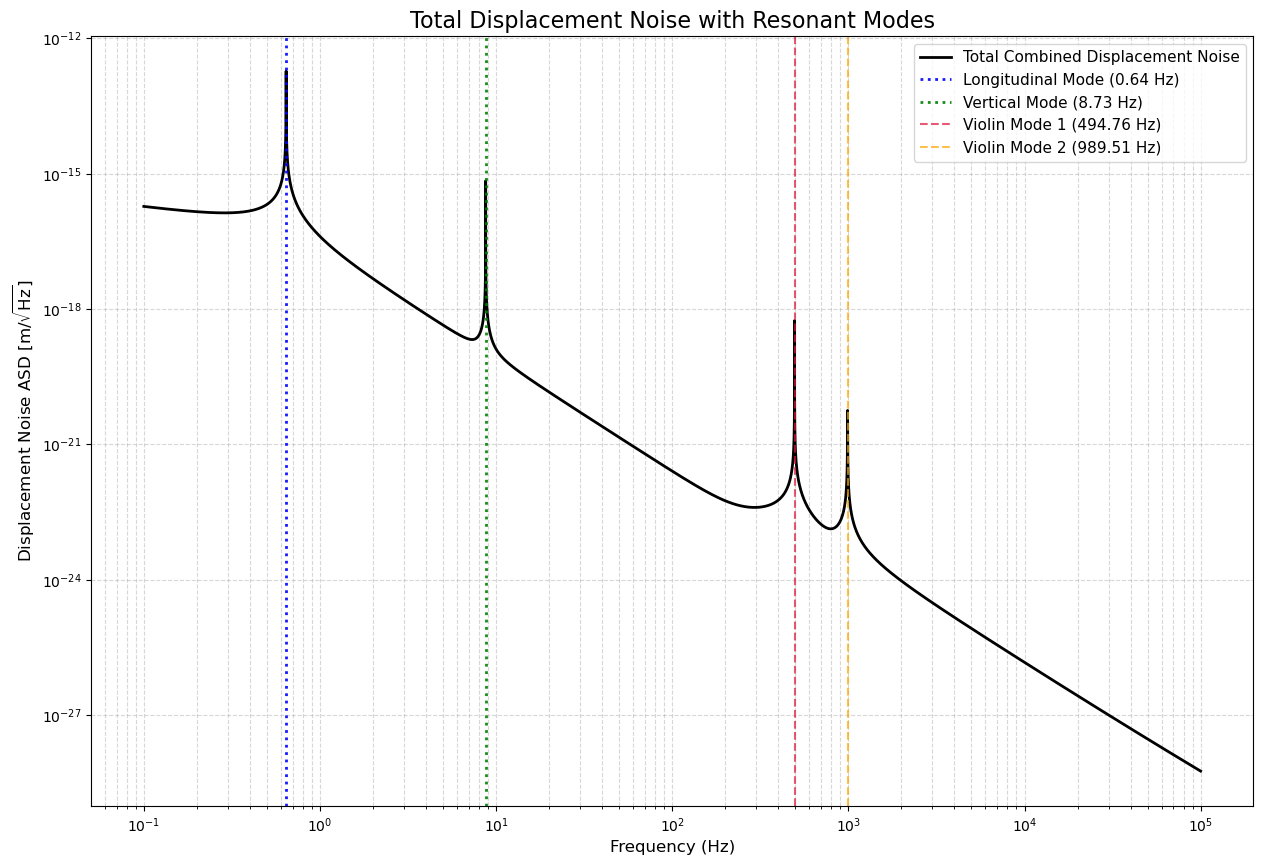

In [10]:
plt.figure(figsize=(15, 10))

f_values = np.logspace(-1, 5, 20000)
x1=psd_values1+psd_values2+total_psd3

#final combined noise curve
plt.loglog(f_values, np.sqrt(x1), label='Total Combined Displacement Noise', color='k', linewidth=2)

# vertical lines to mark the frequency of each mode 

# Longitudinal Mode
plt.axvline(x=f0_hz, color='blue', linestyle=':', linewidth=2, alpha=0.9,label=f'Longitudinal Mode ({f0_hz:.2f} Hz)')

# Vertical Mode
plt.axvline(x=f0_vertical_hz, color='green', linestyle=':', linewidth=2, alpha=0.9, label=f'Vertical Mode ({f0_vertical_hz:.2f} Hz)')

# Violin Mode 1
plt.axvline(x=f1, color='crimson', linestyle='--', alpha=0.7,label=f'Violin Mode 1 ({f1:.2f} Hz)')

# Violin Mode 2
plt.axvline(x=f2, color='orange', linestyle='--', alpha=0.7,label=f'Violin Mode 2 ({f2:.2f} Hz)')

# Plotting
plt.title('Total Displacement Noise with Resonant Modes', fontsize=16)
plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel('Displacement Noise ASD [m/$\\sqrt{\\mathrm{Hz}}$]', fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()

### Final THermal Pendulum 

optimal diameter to nullify thermal Noise =  0.0008222668942759311
Dilution Factor 296.677207510794
Resonant angular frequency ω₀ = 4.036790936266446 rad/s
Resonant frequency f₀ = 0.642475231735365 Hz
Thermal loss matrix =  [0. 0. 0. ... 0. 0. 0.]
Bulk loss matrix =  [2.07185726e-12 2.07295962e-12 2.07406257e-12 ... 8.62775507e-08
 8.63234560e-08 8.63693857e-08]
Surface Loss matrix =  [5.9834587e-08 5.9834587e-08 5.9834587e-08 ... 5.9834587e-08 5.9834587e-08
 5.9834587e-08]
Total loss =  [2.07302989e-10 2.07302993e-10 2.07302996e-10 ... 4.98108877e-10
 4.98263609e-10 4.98418422e-10]


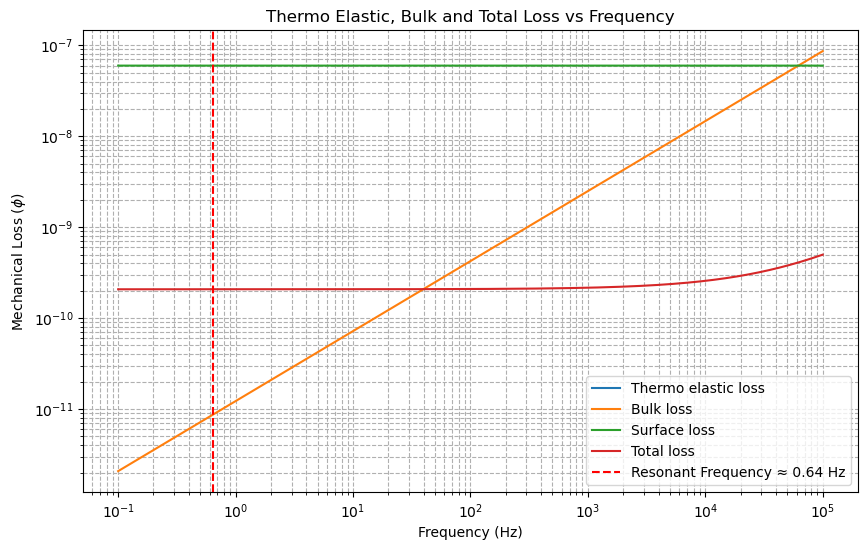

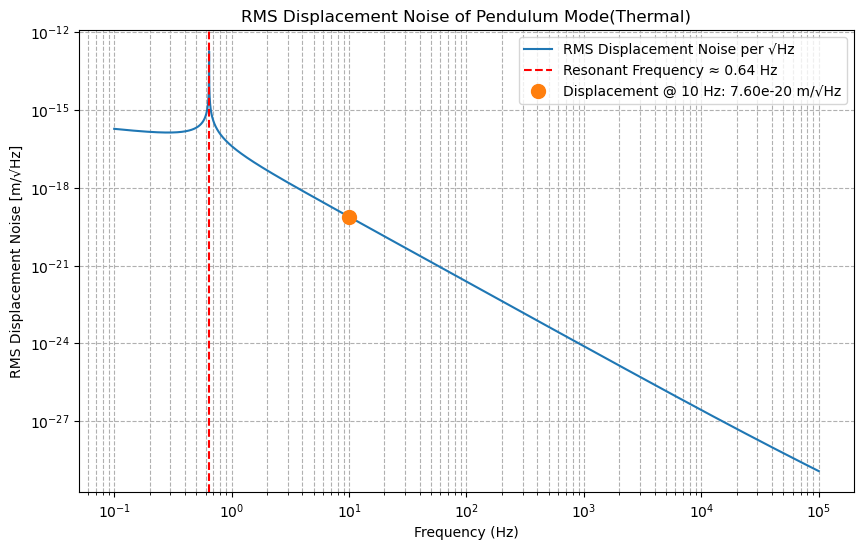

Resonant angular frequency ω₀ = 4.036790936266446 rad/s
Resonant frequency f₀ = 0.642475231735365 Hz


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
k_B = 1.380649e-23 #m^2 kg s^-2 K^-1
T = 300 #K   
m = 10#mass            
g = 9.81 #m/s^2         
l = 0.602 #m
Y = 72e9 #(N/m²)/Pa
rho=2200 #density
C=703#specific heat
alpha=3.9e-7 #coefficient of thermal expansion
d=800e-6 #diameter of the fiber
C2=1.22e-11
hphi_s=6.15e-12 #product of the mechanical loss of the material surface, φs and the depth ,h
beta=1.52e-4 #
Kappa=1.38 #W/mK (thermal Conductivity)

#*****************************************************************#
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)
print("optimal diameter to nullify thermal Noise = ",optimal_diameter)
#*****************************************************************#

###################################################################
sigma_0 = (m* g) / (np.pi * (optimal_diameter / 2)**2) #static stress(F/Area)
###################################################################

###################################################################
#Thermal Relaxation time to nullify Thermal Loss
tau=(1/(4.32*np.pi))*(rho*C*optimal_diameter*optimal_diameter)/Kappa 
###################################################################

###################################################################
#Moment of Inertia
I=np.pi*optimal_diameter**4/64 
###################################################################

Dil_Fact1=2*l*(np.sqrt((m*g)/(Y*I)))
print("Dilution Factor",Dil_Fact1)

omega_0 = np.sqrt(g / l) # resonant angular frequency
print("Resonant angular frequency ω₀ =", omega_0, "rad/s")
f0_hz = omega_0 / (2 * np.pi)# resonant frequency
print("Resonant frequency f₀ =", f0_hz, "Hz")

# Frequency range: 0.1 Hz to 100000 Hz
f_values = np.logspace(-1, 5, 20000)
omega_values = 2 * np.pi * f_values

###################################################################
#Thermo elastic loss
def phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau):
    thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    prefactor = (Y * T) / (rho * C)
    return prefactor * thermo_factor * ((omega_values * tau) / (1 + (omega_values * tau)**2))
Thermo_phi1=phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau)
print("Thermal loss matrix = ",Thermo_phi1)
###################################################################


###################################################################
#bul loss
def phi_bulk1(omega_values, C2):
    return C2 * (omega_values / (2 * np.pi))**0.77
bulk_phi1=phi_bulk1(omega_values, C2)
print("Bulk loss matrix = ",bulk_phi1)
###################################################################


###################################################################
#surface loss
def phi_surface1(hphi_s,optimal_diameter):
    return 8*hphi_s/optimal_diameter
surface_phi1=phi_surface1(hphi_s,optimal_diameter)
array1=np.ones_like(f_values)
surface_phi1=surface_phi1*array1
print("Surface Loss matrix = ",surface_phi1)
###################################################################

###################################################################
#change total phi calculation
def total_phi1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2):
    return phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau) + phi_bulk1(omega_values, C2)+ phi_surface1(hphi_s,d)

phi_total_values1 =total_phi1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2)/Dil_Fact1
print("Total loss = ",phi_total_values1)
###################################################################


def power_spectral_density1(omega, k_B, T, m, omega_0, phi_total_values1):
    numerator = omega_0**2 * phi_total_values1
    denominator = (omega_0**4 * phi_total_values1**2) + (omega_0**2 - omega**2)**2
    prefactor = (4 * k_B * T) / (m * (omega))
    return prefactor * (numerator / denominator)

# Compute PSD
psd_values1 = power_spectral_density1(omega_values, k_B, T, m, omega_0,phi_total_values1)

#printing losses against frequency
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi1, label='Thermo elastic loss')
# Plot Bulk loss
plt.loglog(f_values, bulk_phi1, label='Bulk loss')
# Plot Surface loss
plt.loglog(f_values, surface_phi1, label='Surface loss')
# Plot total loss
plt.loglog(f_values, phi_total_values1, label='Total loss')
# Add the resonant frequency line
plt.axvline(x=f0_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_hz:.2f} Hz')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Loss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()

#Noise at 10 Hz
target_freq = 10.0
#Finding the index of the frequency value closest to 10.0 Hz
idx_10hz = np.argmin(np.abs(f_values - target_freq))
#Actual frequency and the ASD value at that index
actual_freq_at_10hz = f_values[idx_10hz]
displacement_asd_at_10hz = np.sqrt(psd_values1)[idx_10hz]

# Plot RMS Displacement Noise (per √Hz)
plt.figure(figsize=(10, 6))
plt.loglog(f_values, np.sqrt(psd_values1), label='RMS Displacement Noise per √Hz')
plt.axvline(x=f0_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_hz:.2f} Hz')
plt.title('RMS Displacement Noise of Pendulum Mode(Thermal)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/√Hz]')
plt.grid(True, which="both", ls="--")
#Plot Noise at 10Hz
plt.plot(actual_freq_at_10hz, displacement_asd_at_10hz, 'o', markersize=10, label=f'Displacement @ 10 Hz: {displacement_asd_at_10hz:.2e} m/√Hz')
plt.legend()
plt.show()


print("Resonant angular frequency ω₀ =", omega_0, "rad/s")
print("Resonant frequency f₀ =", f0_hz, "Hz")

### Final THermal BOunce


optimal diameter to nullify thermal Noise =  0.0008222668942759311
Dilution Factor 1
fiber Area =  1.2566370614359172e-07
spring constant =  15029.546249731902
Resonant angular frequency ω₀ = 54.82617303757741 rad/s
Resonant frequency f₀ = 8.72585644974204 Hz
Thermal loss matrix =  [0. 0. 0. ... 0. 0. 0.]
Bulk loss matrix =  [2.07185726e-12 2.07295962e-12 2.07406257e-12 ... 8.62775507e-08
 8.63234560e-08 8.63693857e-08]
Surface Loss matrix =  1.23e-07
Surface Loss matrix =  [1.23e-07 1.23e-07 1.23e-07 ... 1.23e-07 1.23e-07 1.23e-07]
Total loss =  [1.23002072e-07 1.23002073e-07 1.23002074e-07 ... 2.09277551e-07
 2.09323456e-07 2.09369386e-07]


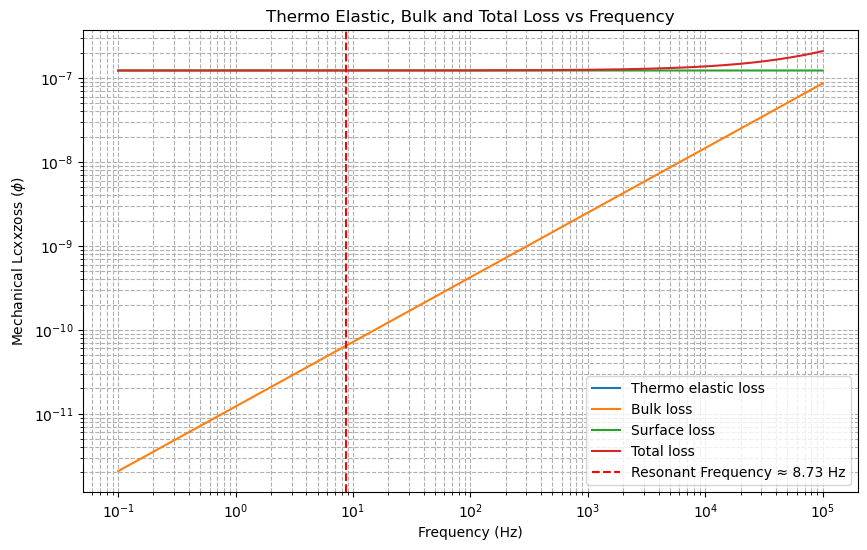

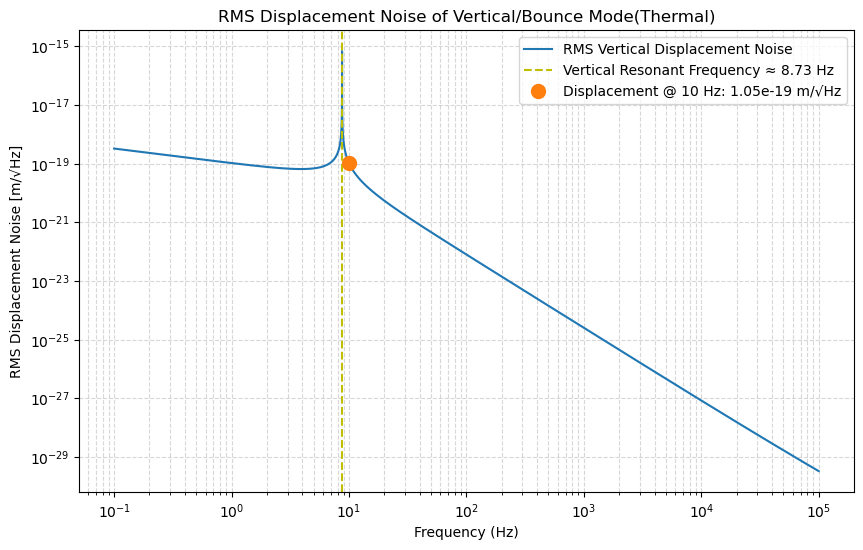

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
k_B = 1.380649e-23 #m^2 kg s^-2 K^-1
T = 300 #K   
m = 10#mass 
m1=((m*m)/(m+m))
g = 9.81 #m/s^2         
l = 0.602 #m
Y = 72e9 #(N/m²)/Pa
rho=2200 #density
C=703#specific heat
alpha=3.9e-7 #coefficient of thermal expansion
d=800e-6 #diameter of the fiber
d1=400e-6
C2=1.22e-11
hphi_s=6.15e-12 #product of the mechanical loss of the material surface, φs and the depth ,h
beta=1.52e-4 #
Kappa=1.38 #W/mK (thermal Conductivity)

#*****************************************************************#
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)
print("optimal diameter to nullify thermal Noise = ",optimal_diameter)
#*****************************************************************#

###################################################################
sigma_0 = (m* g) / (np.pi * (optimal_diameter / 2)**2) #static stress(F/Area)
###################################################################

###################################################################
#Thermal Relaxation time to nullify Thermal Loss
tau=(1/(4.32*np.pi))*(rho*C*optimal_diameter*optimal_diameter)/Kappa 
###################################################################

###################################################################
#Moment of Inertia
I=np.pi*optimal_diameter**4/64 
###################################################################

Dil_Fact2=1
print("Dilution Factor",Dil_Fact2)

A_fiber = np.pi * (d1 / 2)**2 # fiber cross section Area (here 400 microns used as spring mode is at this diameter)
print("fiber Area = ",A_fiber)
k_fiber = (Y * A_fiber) / l #spring constant
print("spring constant = ",k_fiber)
omega_0_vertical = np.sqrt(k_fiber / m1) # Angular Resonant Frequency for vertical mode
print("Resonant angular frequency ω₀ =", omega_0_vertical, "rad/s")
f0_vertical_hz = omega_0_vertical / (2 * np.pi) # vertical resonant freq calculation
print("Resonant frequency f₀ =", f0_vertical_hz, "Hz")
,
# Frequency range: 0.1 Hz to 100000 Hz
f_values = np.logspace(-1, 5, 20000)
omega_values = 2 * np.pi * f_values

###################################################################
#Thermoelastic Loss,set to 0
#def phi_thermo2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau):
    #thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    #prefactor = (Y * T) / (rho * C)
    #return prefactor * thermo_factor * ((omega_values * tau) / (1 + (omega_values * tau)**2))
#Thermo_phi2=phi_thermo2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau)
Thermo_phi2=0*np.ones_like(f_values)
print("Thermal loss matrix = ",Thermo_phi2)
###################################################################

def phi_bulk2(omega, C2):
    return C2 * (omega / (2 * np.pi))**0.77
bulk_phi2=phi_bulk2(omega_values, C2)
print("Bulk loss matrix = ",bulk_phi2)


###################################################################
def phi_surface2(hphi_s, d1):#800 microns/400 microns doubt
    return 8 * hphi_s / d1
surface_phi2=phi_surface2(hphi_s,d1)
print("Surface Loss matrix = ",surface_phi2)
array2=np.ones_like(f_values)
surface_phi2=surface_phi2*array2
print("Surface Loss matrix = ",surface_phi2)
###################################################################

###################################################################
#Total phi
def total_phi2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2, hphi_s, d1):
    surface_loss = phi_surface2(hphi_s, d1)
    return phi_bulk2(omega_values, C2) + surface_loss
phi_total_values2 =total_phi2(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2,hphi_s, d1)/Dil_Fact2
print("Total loss = ",phi_total_values2)
###################################################################

def power_spectral_density2(omega_values, k_B, T, m, omega_0_vertical, phi_total_values2):
    numerator = omega_0_vertical**2 * phi_total_values2
    denominator = (omega_0_vertical**4 * phi_total_values2**2) + (omega_0_vertical**2 - omega_values**2)**2
    prefactor = (4 * k_B * T) / (m * (omega_values))
    return prefactor * (numerator / denominator)

# PSD for vertical freq
psd_values2 = power_spectral_density2(omega_values, k_B, T, m, omega_0_vertical, phi_total_values2)
psd_values2=psd_values2*0.000001

#printing losses against frequency
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi2, label='Thermo elastic loss')
# Plot Bulk loss 
plt.loglog(f_values, bulk_phi2, label='Bulk loss')
# Plot Surface loss 
plt.loglog(f_values, surface_phi2, label='Surface loss')
# Plot Total loss
plt.loglog(f_values, phi_total_values2, label='Total loss')
# Add the resonant frequency line
plt.axvline(x=f0_vertical_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_vertical_hz:.2f} Hz')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Lcxxzoss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()

#Noise at 10 Hz
target_freq = 10.0
#Finding the index of the frequency value closest to 10.0 Hz
idx_10hz = np.argmin(np.abs(f_values - target_freq))
#Actual frequency and the ASD value at that index
actual_freq_at_10hz = f_values[idx_10hz]
displacement_asd_at_10hz = np.sqrt(psd_values2)[idx_10hz]

# Plot
plt.figure(figsize=(10, 6))
plt.loglog(f_values,np.sqrt(psd_values2), label='RMS Vertical Displacement Noise')
plt.axvline(x=f0_vertical_hz, color='y', linestyle='--', label=f'Vertical Resonant Frequency ≈ {f0_vertical_hz:.2f} Hz')

plt.title('RMS Displacement Noise of Vertical/Bounce Mode(Thermal)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/√Hz]')
plt.grid(True, which="both", ls="--", alpha=0.5)
#Plot Noise at 10Hz
plt.plot(actual_freq_at_10hz, displacement_asd_at_10hz, 'o', markersize=10, label=f'Displacement @ 10 Hz: {displacement_asd_at_10hz:.2e} m/√Hz')
plt.legend()
plt.show()


###  Final Thermal Violin 

optimal diameter to nullify thermal Noise =  0.0008222668942759311
Dilution Factor 148.338603755397
Thermal loss matrix =  [0. 0. 0. ... 0. 0. 0.]
Bulk loss matrix =  [2.07185726e-12 2.07295962e-12 2.07406257e-12 ... 8.62775507e-08
 8.63234560e-08 8.63693857e-08]
Surface Loss matrix =  6.15e-08
Surface Loss matrix =  [6.15e-08 6.15e-08 6.15e-08 ... 6.15e-08 6.15e-08 6.15e-08]
Total loss =  [8.29197989e-10 8.29197996e-10 8.29198003e-10 ... 1.41080976e-09
 1.41111923e-09 1.41142886e-09]
Combined Modes: [1, 2]
Violin Mode 1 at f₀ = 494.76 Hz
Violin Mode 2 at f₀ = 989.51 Hz


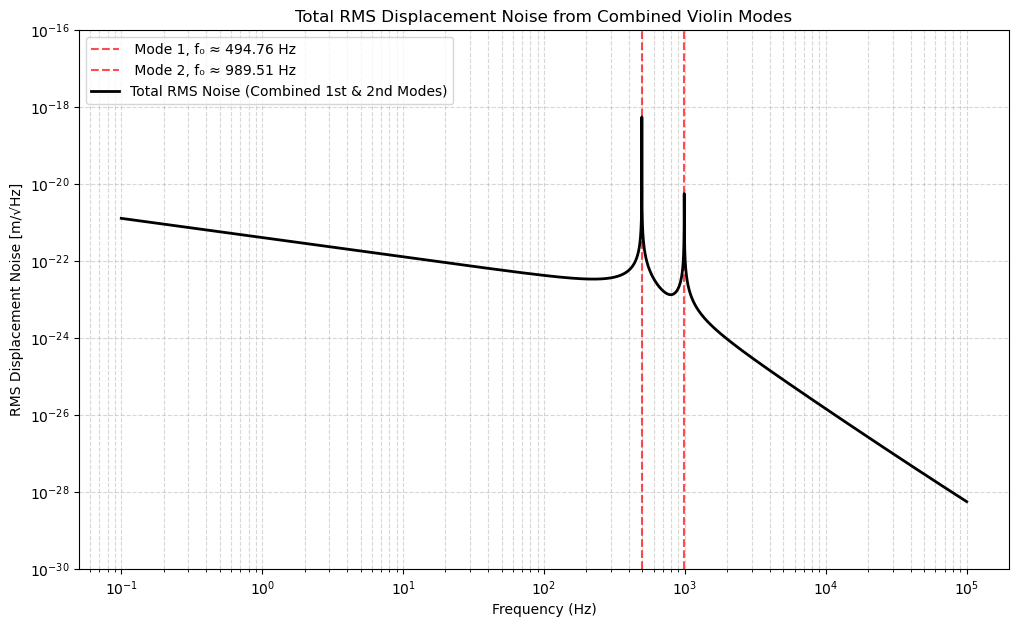

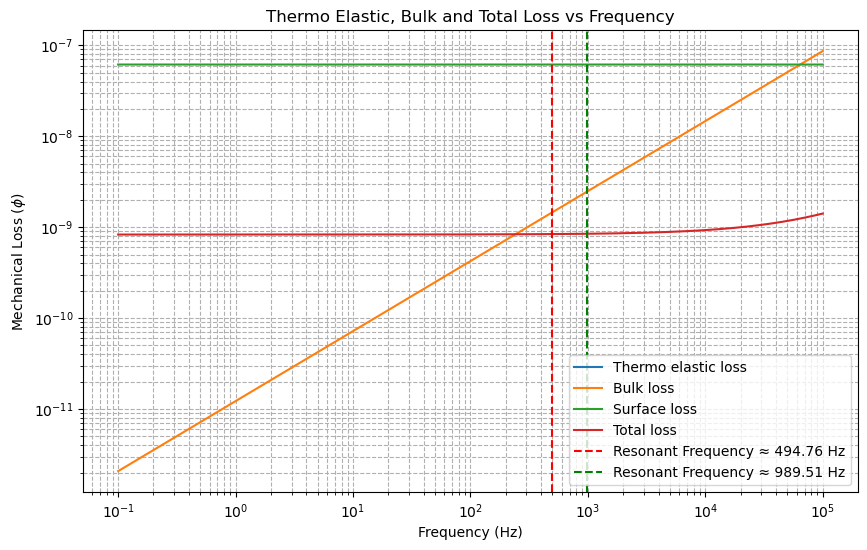

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
k_B = 1.380649e-23 #m^2 kg s^-2 K^-1
T = 300 #K   
m = 10#mass 
m1=((m*m)/(m+m))
g = 9.81 #m/s^2         
l = 0.602 #m
Y = 72e9 #(N/m²)/Pa
rho=2200 #density
C=703#specific heat
alpha=3.9e-7 #coefficient of thermal expansion
d=800e-6 #diameter of the fiber
d1=400e-6
C2=1.22e-11
hphi_s=6.15e-12 #product of the mechanical loss of the material surface, φs and the depth ,h
beta=1.52e-4 #
Kappa=1.38 #W/mK (thermal Conductivity)
vfiber=(np.pi*(3e-3/2)**2)*10e-3+(np.pi*(800e-6/2)**2)*20e-3+(np.pi*(400e-6/2)**2)*596e-3
mfiber=rho*vfiber


#*****************************************************************#
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)
print("optimal diameter to nullify thermal Noise = ",optimal_diameter)
#*****************************************************************#

###################################################################
sigma_0 = (m* g) / (np.pi * (optimal_diameter / 2)**2) #static stress(F/Area)
###################################################################

###################################################################
#Thermal Relaxation time to nullify Thermal Loss
tau=(1/(4.32*np.pi))*(rho*C*optimal_diameter*optimal_diameter)/Kappa 
###################################################################

###################################################################
#Moment of Inertia
I=np.pi*optimal_diameter**4/64 
###################################################################

###################################################################
Dil_Fact3=l*(np.sqrt((m*g)/(Y*I)))#Taken D/2 as per advised
print("Dilution Factor",Dil_Fact3)
###################################################################
f_values = np.logspace(-1, 5, 20000)
omega_values = 2 * np.pi * f_values

T_tension = m * g
A_fiber = np.pi * (d1 / 2)**2
mu = rho * A_fiber

###################################################################
#Thermo Elastic Loss
def phi_thermo3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau):
    thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    prefactor = (Y * T) / (rho * C)
    return prefactor * thermo_factor * ((omega_values * tau) / (1 + (omega_values * tau)**2))
Thermo_phi3=phi_thermo3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau)
print("Thermal loss matrix = ",Thermo_phi3)
###################################################################

#Bulk Loss
def phi_bulk3(omega_values, C2):
    return C2 * (omega_values / (2 * np.pi))**0.77
bulk_phi3=phi_bulk3(omega_values, C2)
print("Bulk loss matrix = ",bulk_phi3)
###################################################################

#Surface loss
def phi_surface3(hphi_s, d):#800 microns/400 microns doubt
    return 8 * hphi_s / d
surface_phi3=phi_surface3(hphi_s,d)
print("Surface Loss matrix = ",surface_phi3)
array3=np.ones_like(f_values)
surface_phi3=surface_phi3*array3
print("Surface Loss matrix = ",surface_phi3)
###################################################################

###################################################################
#Total Phi
def total_phi3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2, hphi_s, d1):
    surface_loss = phi_surface3(hphi_s, d1)
    return phi_thermo3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau) + phi_bulk3(omega_values, C2) + surface_loss
phi_total_values3 =total_phi3(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2,hphi_s, d1)/Dil_Fact3
print("Total loss = ",phi_total_values3)
###################################################################

###################################################################
#PSD
def power_spectral_density3(omega_values, k_B, T, m, omega_0, total_phi_values, mfiber, n):
    numerator = omega_0**2 * total_phi_values
    denominator = (omega_0**4 * total_phi_values**2) + (omega_0**2 - omega_values**2)**2
    prefactor = (4 * k_B * T) * (2 * mfiber) / (m**2 * (np.pi)**2 * n**2)
    return (prefactor / (omega_values)) * (numerator / denominator)
###################################################################

#Total PSD and Plot
total_psd3 = np.zeros_like(f_values)
plt.figure(figsize=(12, 7))

#Sum PSDs
modes = [1, 2]

print("Combined Modes: " + str(modes))
for n in modes:
    #resonant frequency for the current mode 'n'
    f0_violin_hz = (n / (2 * l)) * np.sqrt(T_tension / mu)
    omega_0 = 2 * np.pi * f0_violin_hz
    if n==1:
        f1=f0_violin_hz
    else:
        f2=f0_violin_hz

    psd_values3 = power_spectral_density3(omega_values, k_B, T, m, omega_0, phi_total_values3, mfiber, n)

    #to find total psd
    total_psd3 += psd_values3

    #vertical line to mark the frequency of the individual modes
    plt.axvline(x=f0_violin_hz, color='r', linestyle='--', alpha=0.7, label=f' Mode {n}, f₀ ≈ {f0_violin_hz:.2f} Hz')
    print("Violin Mode "+ str(n)+" at f₀ = " + str(round(f0_violin_hz, 2)) + " Hz")

# Plot the square root of the total PSD to get RMS Displacement Noise
plt.loglog(f_values, np.sqrt(total_psd3), label='Total RMS Noise (Combined 1st & 2nd Modes)', color='k', linewidth=2)

#plot
plt.title('Total RMS Displacement Noise from Combined Violin Modes')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/√Hz]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.ylim(1e-30, 1e-16) # Adjusted y-limits for better viewing
plt.show()


#printing losses against frequency
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi3, label='Thermo elastic loss')
# Plot Bulk loss 
plt.loglog(f_values, bulk_phi3, label='Bulk loss')
# Plot Surface loss 
plt.loglog(f_values, surface_phi3, label='Surface loss')
# Plot Total loss
plt.loglog(f_values, phi_total_values3, label='Total loss')
# Add the resonant frequency line
plt.axvline(x=f1, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f1:.2f} Hz')
# Add the resonant frequency line
plt.axvline(x=f2, color='g', linestyle='--', label=f'Resonant Frequency ≈ {f2:.2f} Hz')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Loss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()


### Final Combined


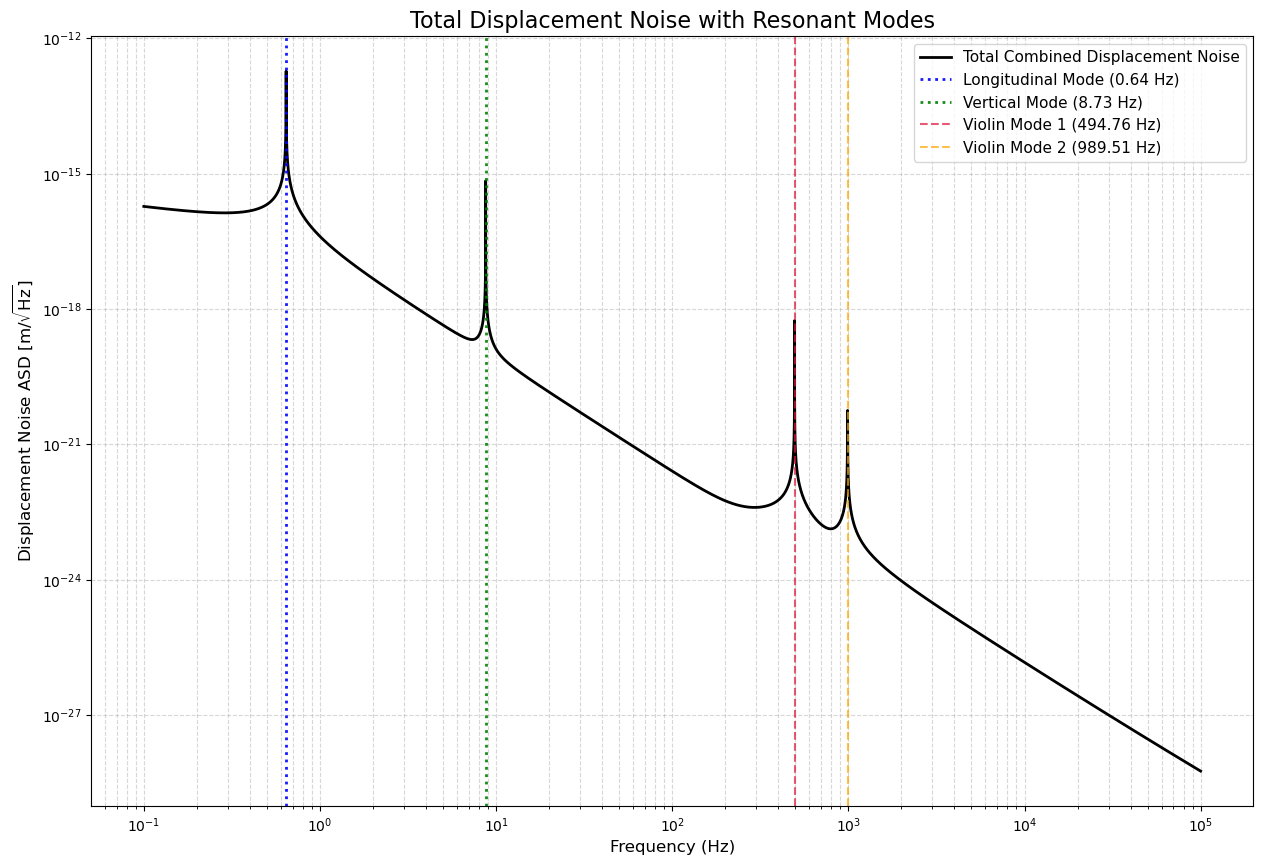

In [10]:
plt.figure(figsize=(15, 10))

f_values = np.logspace(-1, 5, 20000)
x1=psd_values1+psd_values2+total_psd3

#final combined noise curve
plt.loglog(f_values, np.sqrt(x1), label='Total Combined Displacement Noise', color='k', linewidth=2)

# vertical lines to mark the frequency of each mode 

# Longitudinal Mode
plt.axvline(x=f0_hz, color='blue', linestyle=':', linewidth=2, alpha=0.9,label=f'Longitudinal Mode ({f0_hz:.2f} Hz)')

# Vertical Mode
plt.axvline(x=f0_vertical_hz, color='green', linestyle=':', linewidth=2, alpha=0.9, label=f'Vertical Mode ({f0_vertical_hz:.2f} Hz)')

# Violin Mode 1
plt.axvline(x=f1, color='crimson', linestyle='--', alpha=0.7,label=f'Violin Mode 1 ({f1:.2f} Hz)')

# Violin Mode 2
plt.axvline(x=f2, color='orange', linestyle='--', alpha=0.7,label=f'Violin Mode 2 ({f2:.2f} Hz)')

# Plotting
plt.title('Total Displacement Noise with Resonant Modes', fontsize=16)
plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel('Displacement Noise ASD [m/$\\sqrt{\\mathrm{Hz}}$]', fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()
